# 02 — Baselines e modelos de árvore (parte A da tabela geral)

**Trabalho final — Tópicos Especiais em ESSC II (IA aplicada a Séries Temporais)**

Modelos deste notebook (itens 2.3-A e 3.2 do enunciado):

| Grupo | Modelo | Papel |
|---|---|---|
| Baseline ingênua | Classe majoritária | piso de sanidade: o que se acerta sem olhar a série |
| Baseline clássica de classificação | **1-NN + DTW** | referência indicada no enunciado para classificação de séries |
| A1 | Árvore de Decisão | modelo tabular simples |
| A2 | Random Forest e XGBoost | conjuntos de árvores |

Os modelos de árvore recebem a série em **formato tabular** (formato NC do Nielsen, Cap. 10), de duas maneiras:

1. **Janela de defasagens (*lags*):** os 32 instantes × 321 atributos viram 10.272 colunas. É o "janelamento temporal" pedido no enunciado: a janela cobre a série inteira.
2. **Atributos ergódicos** (notebook 01): 4 estatísticas por canal (amplitude, % além de 1 desvio, assimetria e inclinação máxima), 1.284 colunas.

Protocolo: as 4 rodadas por sinalizante do notebook 00, com hiperparâmetros escolhidos **só na validação** e **3 sementes** (0, 1, 2) para os modelos com aleatoriedade.

## 1. Configuração

In [1]:
import sys, subprocess, importlib.util, time, warnings
from pathlib import Path
for pacote in ["tslearn", "xgboost"]:
    if importlib.util.find_spec(pacote) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
import xgboost as xgb
from tslearn.metrics import cdist_dtw

warnings.filterwarnings("ignore", category=UserWarning)
SEMENTES = [0, 1, 2]
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/trabalho_series_temporais")
else:
    BASE = Path.cwd().parent if (Path.cwd().parent / "dados").exists() else Path.cwd()
DADOS, FIG, RES = BASE / "dados", BASE / "figuras", BASE / "resultados"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

def salvar_fig(nome):
    plt.savefig(FIG / f"02_{nome}.png", bbox_inches="tight", dpi=150)

d = np.load(DADOS / "minds_st.npz", allow_pickle=False)
X, y = d["X"], d["y"]
classes, cols = d["classes"].astype(str), d["cols"].astype(str)
sinalizante, grupo, VAL = d["sinalizante"], d["grupo"], d["validacao"]
N, T, F = X.shape
print(f"séries: {N} | T={T} | F={F} | classes: {len(classes)}")

def particao(rodada):
    te = np.where(grupo == rodada)[0]
    va = np.where(np.isin(sinalizante, VAL[rodada]))[0]
    tr = np.setdiff1d(np.arange(N), np.concatenate([te, va]))
    return tr, va, te

def padronizar(X, tr):
    # z-score por canal com média e desvio só do treino da rodada
    mu = X[tr].reshape(-1, X.shape[-1]).mean(0)
    sd = X[tr].reshape(-1, X.shape[-1]).std(0) + 1e-6
    return ((X - mu) / sd).astype(np.float32)

def metricas(y_true, y_pred):
    return dict(acuracia=accuracy_score(y_true, y_pred), acuracia_balanceada=balanced_accuracy_score(y_true, y_pred),
                f1_macro=f1_score(y_true, y_pred, average="macro"))

resultados = []                          # uma linha por (modelo, representação, rodada, semente)
previsoes = {}                           # previsões de teste (semente 0) para a análise por palavra

séries: 1158 | T=32 | F=321 | classes: 20


## 2. As duas representações tabulares

O z-score usa as estatísticas do treino de cada rodada, então a matriz de *lags* é montada **dentro** do laço de rodadas. Os atributos ergódicos são calculados série a série e não dependem da rodada.

Um ponto importante para a discussão: árvores tratam cada coluna como uma variável independente. Se as 10.272 colunas forem embaralhadas (a mesma permutação para todos os vídeos), uma árvore aprende **exatamente o mesmo modelo**. Ela não sabe que a coluna "instante 10" vem antes da "instante 11". Toda a informação de ordem temporal precisa ser "redescoberta" pelos cortes. É a limitação que o Nielsen aponta para modelos de *lags* e o que as redes convolucionais e recorrentes (notebook 03) exploram explicitamente.

In [2]:
def caracteristicas_ergodicas(X):
    mu, sd = X.mean(1, keepdims=True), X.std(1, keepdims=True)
    amplitude = X.max(1) - X.min(1)
    alem_1dp = (np.abs(X - mu) > sd).mean(1)
    ok = sd[:, 0] > 1e-6
    assimetria = np.where(ok, (((X - mu) / np.where(sd > 1e-6, sd, 1)) ** 3).mean(1), 0.0)
    inclinacao_max = np.abs(np.diff(X, axis=1)).max(1)
    return np.concatenate([amplitude, alem_1dp, assimetria, inclinacao_max], axis=1).astype(np.float32)

ERG = caracteristicas_ergodicas(X)
def representacao(nome, tr):
    if nome == "lags":
        return padronizar(X, tr).reshape(N, -1)        # (N, 32*321) = (N, 10272)
    return ERG                                         # (N, 1284)
print("lags:", (N, T * F), "| ergódicos:", ERG.shape)

lags: (1158, 10272) | ergódicos: (1158, 1284)


## 3. Baselines

### 3.1 Classe majoritária

Prevê sempre a palavra mais frequente do treino. Com 20 classes quase balanceadas, deve ficar perto de 5%.

In [3]:
for k in range(4):
    tr, va, te = particao(k)
    maj = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(tr), 1)), y[tr])
    resultados.append(dict(modelo="Classe majoritária", representacao="—", rodada=k, semente=0,
                           **metricas(y[te], maj.predict(np.zeros((len(te), 1))))))
print(pd.DataFrame(resultados).groupby("modelo")[["acuracia", "f1_macro"]].mean().round(3))

                    acuracia  f1_macro
modelo                                
Classe majoritária     0.052     0.005


### 3.2 1-NN + DTW

Cada vídeo de teste recebe a palavra do vídeo de treino mais parecido, medindo a semelhança com o **DTW multivariado dependente** (os 321 canais alinhados juntos, sobre as séries padronizadas com o z-score do treino).

O único hiperparâmetro é a largura da **janela de Sakoe-Chiba** (quantos instantes o alinhamento pode "escorregar"). Ela é escolhida na validação entre 0 (que equivale à distância euclidiana, sem alinhamento), 2, 4, 8 e sem restrição. O 1-NN é determinístico e dispensa sementes.

Tempo esperado: ~2 minutos por rodada.

In [4]:
def distancias(A, B, raio):
    if raio == 0:                                      # sem deformação = distância euclidiana
        a, b = A.reshape(len(A), -1), B.reshape(len(B), -1)
        return np.sqrt(np.maximum((a ** 2).sum(1)[:, None] + (b ** 2).sum(1)[None] - 2 * a @ b.T, 0))
    kw = dict(global_constraint="sakoe_chiba", sakoe_chiba_radius=raio) if raio else {}
    return cdist_dtw(A.astype(np.float64), B.astype(np.float64), **kw)

RAIOS = [0, 2, 4, 8, None]
escolha_raio = []
for k in range(4):
    t_ini = time.time()
    tr, va, te = particao(k)
    Z = padronizar(X, tr)
    f1_val = {}
    for r in RAIOS:
        D = distancias(Z[va], Z[tr], r)
        f1_val[r] = f1_score(y[va], y[tr][D.argmin(1)], average="macro")
    melhor = max(RAIOS, key=lambda r: (f1_val[r], -(r if r is not None else 99)))
    D = distancias(Z[te], Z[tr], melhor)
    pred = y[tr][D.argmin(1)]
    previsoes[("1-NN + DTW", "série")] = previsoes.get(("1-NN + DTW", "série"), np.zeros(N, int))
    previsoes[("1-NN + DTW", "série")][te] = pred
    resultados.append(dict(modelo="1-NN + DTW", representacao="série", rodada=k, semente=0, hiperparametro=f"raio={melhor}",
                           tempo_s=time.time() - t_ini, **metricas(y[te], pred)))
    escolha_raio.append({"rodada": k, **{f"F1 val raio={r}": round(v, 3) for r, v in f1_val.items()}, "escolhido": melhor})
    print(f"rodada {k}: raio escolhido = {melhor} | F1 teste = {resultados[-1]['f1_macro']:.3f} | {time.time() - t_ini:.0f}s")
display(pd.DataFrame(escolha_raio))

rodada 0: raio escolhido = 4 | F1 teste = 0.526 | 89s


rodada 1: raio escolhido = 2 | F1 teste = 0.657 | 76s


rodada 2: raio escolhido = 4 | F1 teste = 0.639 | 83s


rodada 3: raio escolhido = 0 | F1 teste = 0.636 | 68s


,rodada,F1 val raio=0,F1 val raio=2,F1 val raio=4,F1 val raio=8,F1 val raio=None,escolhido
0,0,0.507,0.505,0.529,0.529,0.529,4
1,1,0.581,0.621,0.616,0.616,0.616,2
2,2,0.661,0.683,0.697,0.697,0.693,4
3,3,0.746,0.736,0.735,0.735,0.735,0


## 4. Árvore de Decisão, Random Forest e XGBoost

Busca de hiperparâmetros (pequena, escolhida pelo F1 macro na validação):

| Modelo | Grade | Fixos |
|---|---|---|
| Árvore de Decisão | profundidade máxima ∈ {8, 16, sem limite}; mínimo por folha ∈ {1, 5} | critério Gini |
| Random Forest | atributos por divisão ∈ {√p, 0,05·p} | 500 árvores |
| XGBoost | número de árvores por *early stopping* na validação (30 rodadas sem melhora, até 1.000) | taxa 0,1, profundidade 4, 80% das amostras e 10% das colunas por árvore, 64 faixas de histograma |

Depois da escolha, cada configuração é treinada com as **3 sementes** e avaliada no teste. Tempo esperado: ~30 minutos no total (o XGBoost sobre os *lags* é o mais lento).

In [5]:
GRADE = {
    "Árvore de Decisão": [dict(max_depth=md_, min_samples_leaf=ml) for md_ in [8, 16, None] for ml in [1, 5]],
    "Random Forest": [dict(max_features=mf) for mf in ["sqrt", 0.05]],
}

def criar(nome, params, semente):
    if nome == "Árvore de Decisão":
        return DecisionTreeClassifier(random_state=semente, **params)
    if nome == "Random Forest":
        return RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=semente, **params)
    return xgb.XGBClassifier(n_estimators=1000, learning_rate=0.1, max_depth=4, subsample=0.8, colsample_bytree=0.1,
                             max_bin=64, tree_method="hist", early_stopping_rounds=30, eval_metric="mlogloss",
                             random_state=semente, n_jobs=-1)

def treinar(nome, params, semente, M, tr, va):
    m = criar(nome, params, semente)
    if nome == "XGBoost":
        m.fit(M[tr], y[tr], eval_set=[(M[va], y[va])], verbose=False)
    else:
        m.fit(M[tr], y[tr])
    return m

for rep in ["lags", "ergodicos"]:
    for k in range(4):
        tr, va, te = particao(k)
        M = representacao(rep, tr)
        for nome in ["Árvore de Decisão", "Random Forest", "XGBoost"]:
            # 1) escolha de hiperparâmetros na validação (semente 0)
            if nome in GRADE:
                f1v = [f1_score(y[va], treinar(nome, p, 0, M, tr, va).predict(M[va]), average="macro") for p in GRADE[nome]]
                params = GRADE[nome][int(np.argmax(f1v))]
            else:
                params = {}
            # 2) treino com as 3 sementes e avaliação no teste
            for s in SEMENTES:
                t_ini = time.time()
                m = treinar(nome, params, s, M, tr, va)
                t_treino = time.time() - t_ini
                pred = m.predict(M[te])
                extra = f"árvores={m.best_iteration + 1}" if nome == "XGBoost" else str(params)
                resultados.append(dict(modelo=nome, representacao=rep, rodada=k, semente=s, hiperparametro=extra,
                                       tempo_s=t_treino, **metricas(y[te], pred)))
                if s == 0:
                    previsoes.setdefault((nome, rep), np.zeros(N, int))[te] = pred
            ult = pd.DataFrame(resultados[-3:])
            print(f"[{rep:9s}] rodada {k} {nome:18s} F1 teste = {ult.f1_macro.mean():.3f} ± {ult.f1_macro.std():.3f} "
                  f"| {extra} | {ult.tempo_s.mean():.0f}s por treino", flush=True)

res = pd.DataFrame(resultados)
res.to_csv(RES / "02_resultados_por_rodada.csv", index=False)

[lags     ] rodada 0 Árvore de Decisão  F1 teste = 0.739 ± 0.007 | {'max_depth': 16, 'min_samples_leaf': 5} | 3s por treino


[lags     ] rodada 0 Random Forest      F1 teste = 0.906 ± 0.007 | {'max_features': 'sqrt'} | 6s por treino


[lags     ] rodada 0 XGBoost            F1 teste = 0.931 ± 0.021 | árvores=212 | 79s por treino


[lags     ] rodada 1 Árvore de Decisão  F1 teste = 0.718 ± 0.034 | {'max_depth': 16, 'min_samples_leaf': 1} | 3s por treino


[lags     ] rodada 1 Random Forest      F1 teste = 0.902 ± 0.001 | {'max_features': 'sqrt'} | 6s por treino


[lags     ] rodada 1 XGBoost            F1 teste = 0.866 ± 0.003 | árvores=165 | 82s por treino


... (14 outputs left out)

[ergodicos] rodada 2 XGBoost            F1 teste = 0.725 ± 0.011 | árvores=150 | 10s por treino


[ergodicos] rodada 3 Árvore de Decisão  F1 teste = 0.499 ± 0.024 | {'max_depth': 16, 'min_samples_leaf': 1} | 0s por treino


[ergodicos] rodada 3 Random Forest      F1 teste = 0.783 ± 0.007 | {'max_features': 'sqrt'} | 2s por treino


[ergodicos] rodada 3 XGBoost            F1 teste = 0.798 ± 0.003 | árvores=298 | 14s por treino


## 5. Tabela comparativa (parte A da tabela geral)

Média e desvio padrão sobre **rodadas × sementes** (4 × 3 = 12 avaliações por modelo; 4 para os determinísticos). O desvio mistura duas fontes de variação: quais pessoas estão no teste e a semente.

In [6]:
ordem = ["Classe majoritária", "1-NN + DTW", "Árvore de Decisão", "Random Forest", "XGBoost"]
tab = (res.groupby(["modelo", "representacao"])[["acuracia", "acuracia_balanceada", "f1_macro", "tempo_s"]]
          .agg(["mean", "std"]).reindex(ordem, level=0))
fmt = pd.DataFrame(index=tab.index)
for m in ["acuracia", "acuracia_balanceada", "f1_macro"]:
    fmt[m] = (100 * tab[(m, "mean")]).map("{:.1f}".format) + " ± " + (100 * tab[(m, "std")]).fillna(0).map("{:.1f}".format)
fmt["tempo de treino (s)"] = tab[("tempo_s", "mean")].map(lambda v: "—" if pd.isna(v) else f"{v:.1f}")
display(fmt)
tab.to_csv(RES / "02_tabela_parteA.csv")

acuracia acuracia_balanceada    f1_macro  \
modelo             representacao                                               
Classe majoritária —               5.2 ± 0.2           5.0 ± 0.0   0.5 ± 0.0   
1-NN + DTW         série          62.1 ± 4.8          61.8 ± 5.4  61.5 ± 6.0   
Árvore de Decisão  ergodicos      51.7 ± 7.7          51.4 ± 7.5  49.1 ± 8.7   
                   lags           72.2 ± 3.0          72.2 ± 3.1  71.2 ± 2.7   
Random Forest      ergodicos      76.0 ± 2.9          76.0 ± 3.3  74.9 ± 4.0   
                   lags           90.2 ± 2.8          89.8 ± 3.1  89.0 ± 3.6   
XGBoost            ergodicos      75.1 ± 4.3          74.6 ± 5.2  73.5 ± 6.3   
                   lags           88.5 ± 3.9          88.1 ± 3.6  87.6 ± 3.7   

                                 tempo de treino (s)  
modelo             representacao                      
Classe majoritária —                               —  
1-NN + DTW         série                        78.9  
Árvore de Decisão  ergodicos                     0.3  
                   lags                          3.4  
Random Forest      ergodicos                     3.2  
                   lags                          5.9  
XGBoost            ergodicos                    13.1  
                   lags                         74.8

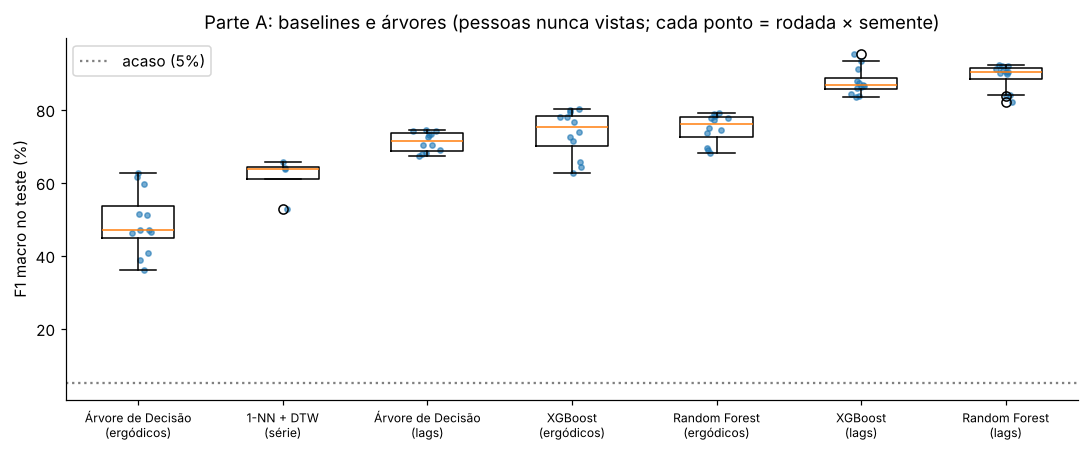

In [7]:
r = res[res.modelo != "Classe majoritária"].copy()
r["config"] = r.modelo + "\n(" + r.representacao.str.replace("ergodicos", "ergódicos") + ")"
cfgs = r.groupby("config").f1_macro.mean().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.boxplot([100 * r[r.config == c].f1_macro for c in cfgs], tick_labels=cfgs)
for j, c in enumerate(cfgs, 1):
    v = 100 * r[r.config == c].f1_macro
    ax.scatter(np.random.normal(j, .04, len(v)), v, s=12, alpha=.6, color="tab:blue")
maj = 100 * res[res.modelo == "Classe majoritária"].f1_macro.mean()
ax.axhline(100 / 20, ls=":", color="gray", label="acaso (5%)")
ax.set_ylabel("F1 macro no teste (%)"); ax.set_title("Parte A: baselines e árvores (pessoas nunca vistas; cada ponto = rodada × semente)")
ax.tick_params(axis="x", labelsize=8); ax.legend(); plt.tight_layout(); salvar_fig("comparacao_parteA"); plt.show()

## 6. Onde os modelos erram

Matriz de confusão do melhor modelo de árvore e F1 por palavra dos principais modelos (semente 0, as 4 rodadas juntas: cada vídeo aparece uma vez como teste).

,1-NN + DTW (série),Random Forest (lags),XGBoost (lags),Random Forest (ergodicos),XGBoost (ergodicos)
medo,55,63,79,66,70
filho,45,69,76,62,58
aproveitar,53,76,90,78,74
cinco,44,81,85,70,70
aluno,62,83,78,78,75
vacina,62,90,83,79,87
banheiro,82,90,77,52,57
conhecer,29,92,93,78,72
banco,62,94,91,73,66
bala,38,94,89,79,77


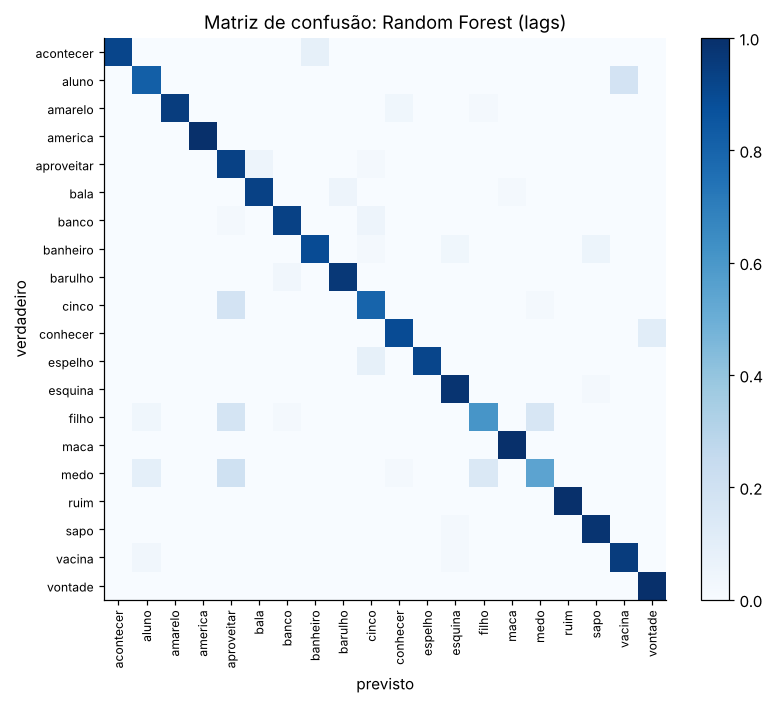

,verdadeiro,previsto como,fração
289,medo,aproveitar,0.20
36,aluno,vacina,0.18
175,cinco,aproveitar,0.18
251,filho,aproveitar,0.18
261,filho,medo,0.16
298,medo,filho,0.15


In [8]:
f1_pal = pd.DataFrame({f"{m} ({r})": f1_score(y, p, average=None) for (m, r), p in previsoes.items()}, index=classes)
f1_pal = f1_pal[[c for c in f1_pal.columns if "Árvore" not in c]]
melhor = f1_pal.mean().idxmax()
display((100 * f1_pal.sort_values(melhor)).round(0).astype(int))

chave = next(k for k in previsoes if f"{k[0]} ({k[1]})" == melhor)
cm = confusion_matrix(y, previsoes[chave], normalize="true")
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(20), classes, rotation=90, fontsize=8); ax.set_yticks(range(20), classes, fontsize=8)
ax.set_xlabel("previsto"); ax.set_ylabel("verdadeiro"); ax.set_title(f"Matriz de confusão: {melhor}")
plt.colorbar(im, ax=ax, fraction=.046); plt.tight_layout(); salvar_fig("confusao_melhor_arvore"); plt.show()

conf = pd.DataFrame([(classes[i], classes[j], cm[i, j]) for i in range(20) for j in range(20) if i != j],
                    columns=["verdadeiro", "previsto como", "fração"]).nlargest(6, "fração").round(2)
display(conf)

## 7. Desempenho por sinalizante

Como cada rodada testa 3 pessoas diferentes, vale ver se há sinalizantes muito mais difíceis (por exemplo, por estilo de sinalização ou por falhas de detecção da mão).

In [9]:
por_pessoa = pd.DataFrame({f"{m} ({r})": [accuracy_score(y[sinalizante == s], p[sinalizante == s]) for s in range(1, 13)]
                           for (m, r), p in previsoes.items() if "Árvore" not in m}, index=[f"S{s:02d}" for s in range(1, 13)])
display((100 * por_pessoa).round(1))
por_pessoa.to_csv(RES / "02_acuracia_por_sinalizante.csv")

,1-NN + DTW (série),Random Forest (lags),XGBoost (lags),Random Forest (ergodicos),XGBoost (ergodicos)
S01,59.0,89.0,92.0,68.0,69.0
S02,81.0,98.0,98.0,93.0,87.0
S03,60.0,89.4,98.8,65.9,60.0
S04,48.4,88.4,72.6,57.9,60.0
S05,48.0,91.0,94.0,76.0,67.0
S06,63.0,87.0,84.0,79.0,79.0
S07,64.1,80.6,84.5,70.9,76.7
S08,74.0,95.0,87.0,94.0,92.0
S09,60.0,97.3,88.0,69.3,70.7
S10,55.0,87.0,80.0,62.0,66.0


## 8. Síntese para o artigo

In [10]:
resumo = res.groupby(["modelo", "representacao"]).f1_macro.agg(["mean", "std"]).reindex(ordem, level=0)
for (m, rep), row in resumo.iterrows():
    print(f"{m:20s} {rep:10s} F1 macro = {100 * row['mean']:.1f}% ± {100 * (0 if pd.isna(row['std']) else row['std']):.1f}")

Classe majoritária   —          F1 macro = 0.5% ± 0.0
1-NN + DTW           série      F1 macro = 61.5% ± 6.0
Árvore de Decisão    ergodicos  F1 macro = 49.1% ± 8.7
Árvore de Decisão    lags       F1 macro = 71.2% ± 2.7
Random Forest        ergodicos  F1 macro = 74.9% ± 4.0
Random Forest        lags       F1 macro = 89.0% ± 3.6
XGBoost              ergodicos  F1 macro = 73.5% ± 6.3
XGBoost              lags       F1 macro = 87.6% ± 3.7


**Leitura:**

- **As baselines delimitam o problema.** A classe majoritária fica no acaso (5% de acurácia). O 1-NN + DTW, sem nenhum treino, acerta ~62% das palavras de pessoas nunca vistas, 12 vezes o acaso.
- **O alinhamento do DTW ajudou pouco.** Na validação, a janela de Sakoe-Chiba ganhou da distância euclidiana (raio 0) por 1 a 4 pontos de F1 em três rodadas e perdeu na quarta. A defasagem entre sinalizantes existe (notebook 01), mas não é o principal obstáculo: com 321 canais, a distância é dominada pelos canais ruidosos (a outra mão está ausente em 42% dos instantes), e todos pesam igual.
- **Janela de *lags* × atributos ergódicos.** Com a série inteira como colunas, o Random Forest sobe de 74,9% para **89,0%** de F1 e o XGBoost de 73,5% para 87,6%. As estatísticas ergódicas descartam *quando* cada coisa acontece, e essa informação de fase e de ordem é decisiva para distinguir os sinais.
- **Árvore única × conjuntos.** A Árvore de Decisão isolada fica em 71%: com ~670 exemplos e 10 mil colunas, ela decora o treino. A média de 500 árvores descorrelacionadas (RF) ganha 18 pontos. Aqui o RF, sem nenhum ajuste fino, empatou com o XGBoost (as diferenças ficam dentro do desvio entre rodadas) e treina 12 vezes mais rápido.
- **Pessoas mais difíceis:** os sinalizantes 4, 7 e 10 ficam abaixo da média em quase todos os modelos. É a variação entre pessoas que a divisão por sinalizante expõe.
- **Palavras confundidas:** *medo*, *filho*, *cinco* e *aproveitar* se confundem entre si, provavelmente por terem locação e movimento parecidos e se diferenciarem pela configuração de mão.
- **Limite dos modelos tabulares.** As árvores não sabem que as colunas são instantes consecutivos (seção 2). Mesmo assim, são uma referência forte: o notebook 03 testa se modelos que exploram essa estrutura (convoluções e recorrências) conseguem superá-las.